# 14 · Focal-leaf-only metrics (from-scratch test set)

Scores the app's model **only on the labelled focal leaf**. The photos are the ones labelled from scratch, with no
model pre-labels (`powdery-mildew-ds2-scratch-test`).

Notebook 13 counted every predicted leaf near the focal leaf. Slivers of neighbouring leaves therefore became false
positives and pulled leaf precision down. Here:

| Class | What is scored |
|---|---|
| `leaf` | Only the leaf the app uses: the **largest predicted leaf** (holes filled), against the labelled focal leaf. |
| `leaf_spot`, `powdery_mildew` | Predicted instances with at least half their area **inside the labelled focal leaf** (no margin). Labels: all spots and mildew on that leaf. |

The model sees the **full photo** exactly as in the app (EXIF-oriented, long side 1280, model input 1024 like the exported ONNX). Results:
- **Instance:** precision, recall and F1 at the app's thresholds (mask IoU ≥ 0.5), plus COCO mask AP50 / AP50-95.
- **Pixel, inside the focal leaf:** precision, recall, F1 and IoU per class.
- **Coverage % of the focal leaf:** MAE and bias.
- **Ultralytics `val`:** run on photos greyed outside the focal leaf with no margin, giving its own table and plots.

95 % CIs come from a bootstrap over photos. With 8 photos, expect them to be wide.

In [1]:
import collections
import csv
import json
import os
import shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import yaml
from dotenv import load_dotenv
from IPython.display import Image as IPImage, display
from matplotlib.colors import ListedColormap
from PIL import Image, ImageOps
from pycocotools import mask as mask_utils
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ultralytics import YOLO

from eval_utils import CLASSES, DISEASES, coverage_primary_leaf, ensure_dataset, fill_holes, paint_class_map

ROOT = Path.cwd()
load_dotenv(ROOT / ".env")  # ROBOFLOW_API_KEY lives here (gitignored); never paste the key into a notebook
PROJECT, VERSION = "powdery-mildew-ds2-scratch-test", 1
CHECKPOINT = ROOT / "runs" / "yolo26x-seg_data-v2" / "weights" / "best.pt"
THRESH = {"leaf": 0.20, "leaf_spot": 0.25, "powdery_mildew": 0.30}  # backend/app/config.py
APP_SIDE = 1280  # backend: photo long side capped at 1280 (routes/scans.py load_image)
APP_IMGSZ = 1024  # model input the app runs at: the exported ONNX size, same as training
MATCH_IOU = 0.5
GREY = (114, 114, 114)
N_BOOT, SEED = 1000, 0
OUT = ROOT / "results" / f"focal_leaf_only_{PROJECT}-v{VERSION}"
OUT.mkdir(parents=True, exist_ok=True)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
CLASS_COLOR = {"leaf": SERIES[0], "leaf_spot": SERIES[1], "powdery_mildew": SERIES[2]}
METRIC_COLOR = {"precision": SERIES[0], "recall": SERIES[1], "f1": SERIES[2], "iou": SERIES[3]}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2, "savefig.dpi": 150, "savefig.bbox": "tight",
})
MAP_COLORS = ListedColormap(["#f0efec", "#b7d3f6", CLASS_COLOR["leaf_spot"], CLASS_COLOR["powdery_mildew"]])
print("checkpoint:", CHECKPOINT.relative_to(ROOT), "| results ->", OUT.relative_to(ROOT))

checkpoint: runs\yolo26x-seg_data-v2\weights\best.pt | results -> results\focal_leaf_only_powdery-mildew-ds2-scratch-test-v1


c:\Users\bp67339\PCPL\plant disease detection\training\training_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data

In [2]:
coco_dir, yolo_yaml = ensure_dataset(ROOT, PROJECT, VERSION, os.environ["ROBOFLOW_API_KEY"], os.environ["ROBOFLOW_WORKSPACE"])
gt = COCO(str(coco_dir / "test" / "_annotations.coco.json"))
CAT = {c["id"]: c["name"] for c in gt.loadCats(gt.getCatIds())}
CAT_ID = {n: i for i, n in CAT.items() if n in CLASSES}
images = sorted(gt.loadImgs(gt.getImgIds()), key=lambda im: im["file_name"])


def app_image(path):
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    im.thumbnail((APP_SIDE, APP_SIDE), Image.Resampling.LANCZOS)
    return im


def gt_at(img, size):
    w, h = size
    sx, sy = w / img["width"], h / img["height"]
    out = {c: [] for c in CLASSES[1:]}
    for a in gt.loadAnns(gt.getAnnIds(imgIds=img["id"])):
        name = CAT[a["category_id"]]
        polys = [[v * (sx if k % 2 == 0 else sy) for k, v in enumerate(p)] for p in a["segmentation"] if len(p) >= 6]
        if name in out and polys:
            out[name].append(mask_utils.decode(mask_utils.merge(mask_utils.frPyObjects(polys, h, w))).astype(bool))
    return out


def focal_leaf(g):
    if not g["leaf"]:
        return None
    return fill_holes(np.logical_or.reduce(g["leaf"] + g["leaf_spot"] + g["powdery_mildew"]))


def rle(m):
    r = mask_utils.encode(np.asfortranarray(m.astype(np.uint8)))
    r["counts"] = r["counts"].decode()
    return r


counts = collections.Counter(CAT[a["category_id"]] for a in gt.loadAnns(gt.getAnnIds()))
print(f"{len(images)} photos | labelled: {dict((c, counts[c]) for c in CLASSES[1:])}")

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
8 photos | labelled: {'leaf': 8, 'leaf_spot': 94, 'powdery_mildew': 118}


## Predict (full photo, like the app) and keep only the focal leaf

In [3]:
model = YOLO(CHECKPOINT)
per_image, gt_coco_dict, dets = [], {"images": [], "annotations": [], "categories": [{"id": i, "name": n} for n, i in CAT_ID.items()]}, []
for img in images:
    name = img["file_name"]
    im = app_image(coco_dir / "test" / name)
    g = gt_at(img, im.size)
    leaf_gt = focal_leaf(g)
    if leaf_gt is None:
        print("no leaf label, skipped:", name)
        continue
    h, w = leaf_gt.shape
    r = model.predict(im, imgsz=APP_IMGSZ, conf=min(THRESH.values()), iou=0.7, retina_masks=True, max_det=300, verbose=False)[0]
    preds = []
    if r.masks is not None:
        for m, c, s in zip(r.masks.data.cpu().numpy().astype(bool), r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy()):
            n = r.names[int(c)]
            if s >= THRESH[n] and m.any():
                preds.append((n, float(s), m))
    leaves = sorted(((s, fill_holes(m)) for n, s, m in preds if n == "leaf"), key=lambda x: -int(x[1].sum()))
    primary_conf, primary = leaves[0] if leaves else (0.0, np.zeros((h, w), bool))
    lesions = [(n, s, m) for n, s, m in preds if n != "leaf" and (m & leaf_gt).sum() >= 0.5 * m.sum()]
    n_other_leaves = len(leaves) - 1 if leaves else 0

    # ground truth / predictions for COCO + matching: one leaf + the lesions on it
    gt_coco_dict["images"].append({"id": img["id"], "file_name": name, "width": w, "height": h})
    gt_inst = {"leaf": [rle(leaf_gt)], **{d: [rle(m) for m in g[d]] for d in DISEASES}}
    for c, rs in gt_inst.items():
        for x in rs:
            gt_coco_dict["annotations"].append({"id": len(gt_coco_dict["annotations"]) + 1, "image_id": img["id"],
                                                "category_id": CAT_ID[c], "segmentation": x, "iscrowd": 0,
                                                "area": float(mask_utils.area(x)), "bbox": list(mask_utils.toBbox(x))})
    dt_inst = {"leaf": [(primary_conf, rle(primary))] if leaves else [],
               **{d: [(s, rle(m)) for n, s, m in lesions if n == d] for d in DISEASES}}
    for c, ds in dt_inst.items():
        dets += [{"image_id": img["id"], "category_id": CAT_ID[c], "segmentation": x, "score": s} for s, x in ds]

    # pixel maps: leaf scored over the whole image, diseases only inside the labelled leaf
    gt_map = paint_class_map(sum((g[c] for c in CLASSES[1:]), []), sum(([c] * len(g[c]) for c in CLASSES[1:]), []), (h, w))
    gt_map[leaf_gt & (gt_map == 0)] = CLASSES.index("leaf")  # filled holes count as leaf
    pred_map = paint_class_map([primary] + [m for _, _, m in lesions], ["leaf"] + [n for n, _, _ in lesions], (h, w))
    pix = {"leaf": {"tp": int((primary & leaf_gt).sum()), "fp": int((primary & ~leaf_gt).sum()), "fn": int((~primary & leaf_gt).sum())}}
    for d in DISEASES:
        k = CLASSES.index(d)
        p, t = (pred_map == k) & leaf_gt, (gt_map == k) & leaf_gt
        pix[d] = {"tp": int((p & t).sum()), "fp": int((p & ~t).sum()), "fn": int((~p & t).sum())}
    area = leaf_gt.sum()
    cov_gt = {d: 100 * ((gt_map == CLASSES.index(d)) & leaf_gt).sum() / area for d in DISEASES}
    cov_pred = {d: 100 * ((pred_map == CLASSES.index(d)) & leaf_gt).sum() / area for d in DISEASES}
    cov_app = coverage_primary_leaf([m for _, _, m in preds], [n for n, _, _ in preds]) or {d: 0.0 for d in DISEASES}
    per_image.append({"file": name, "gt_inst": gt_inst, "dt_inst": dt_inst, "pix": pix, "cov_gt": cov_gt,
                      "cov_pred": cov_pred, "cov_app": cov_app, "other_leaves_ignored": n_other_leaves,
                      "maps": (gt_map, pred_map, leaf_gt), "im": im})
print(f"scored {len(per_image)} photos | neighbouring-leaf predictions ignored: "
      f"{sum(p['other_leaves_ignored'] for p in per_image)} | lesions kept: "
      f"{dict(collections.Counter(d['category_id'] for d in dets))} (category ids {CAT_ID})")

scored 8 photos | neighbouring-leaf predictions ignored: 134 | lesions kept: {1: 8, 2: 128, 3: 128} (category ids {'leaf': 1, 'leaf_spot': 2, 'powdery_mildew': 3})


## Metrics

In [4]:
def match(gt_rles, dt):
    # Greedy one-to-one matching by score at mask IoU >= MATCH_IOU -> (tp, fp, fn)
    if not gt_rles or not dt:
        return 0, len(dt), len(gt_rles)
    dt = sorted(dt, key=lambda x: -x[0])
    ious = np.asarray(mask_utils.iou([x for _, x in dt], gt_rles, [0] * len(gt_rles))).reshape(len(dt), len(gt_rles))
    used, tp = set(), 0
    for i in range(len(dt)):
        free = [j for j in range(len(gt_rles)) if j not in used]
        if free:
            j = max(free, key=lambda j: ious[i, j])
            if ious[i, j] >= MATCH_IOU:
                used.add(j); tp += 1
    return tp, len(dt) - tp, len(gt_rles) - tp


for p in per_image:
    p["inst"] = {c: match(p["gt_inst"][c], p["dt_inst"][c]) for c in CLASSES[1:]}


def prf(tp, fp, fn):
    pr, rc = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return {"precision": pr, "recall": rc, "f1": 2 * pr * rc / max(pr + rc, 1e-9), "iou": tp / max(tp + fp + fn, 1)}


def scores(rows):
    out = {}
    for c in CLASSES[1:]:
        tp, fp, fn = (sum(r["inst"][c][i] for r in rows) for i in range(3))
        for k, v in prf(tp, fp, fn).items():
            if k != "iou":
                out[f"instance.{c}.{k}"] = v
        ptp, pfp, pfn = (sum(r["pix"][c][k] for r in rows) for k in ("tp", "fp", "fn"))
        for k, v in prf(ptp, pfp, pfn).items():
            out[f"pixel.{c}.{k}"] = v
    for d in DISEASES:
        e = np.array([r["cov_pred"][d] - r["cov_gt"][d] for r in rows])
        ea = np.array([r["cov_app"][d] - r["cov_gt"][d] for r in rows])
        out[f"coverage.{d}.mae"], out[f"coverage.{d}.bias"] = float(np.abs(e).mean()), float(e.mean())
        out[f"coverage_app_rule.{d}.mae"] = float(np.abs(ea).mean())
    return out


rng = np.random.default_rng(SEED)
point = scores(per_image)
boots = [scores([per_image[i] for i in rng.integers(0, len(per_image), len(per_image))]) for _ in range(N_BOOT)]
RESULTS = {k: {"value": v, "ci95": [float(np.percentile([b[k] for b in boots], 2.5)), float(np.percentile([b[k] for b in boots], 97.5))]}
           for k, v in point.items()}

gt_c = COCO(); gt_c.dataset = gt_coco_dict; gt_c.createIndex()
ev = COCOeval(gt_c, gt_c.loadRes(dets), "segm"); ev.params.maxDets = [10, 100, 300]
ev.evaluate(); ev.accumulate()
AP = {}
for k, cid in enumerate(ev.params.catIds):
    p = ev.eval["precision"][:, :, k, 0, -1]
    name = next(n for n, i in CAT_ID.items() if i == cid)
    AP[name] = {"ap50": float(p[0][p[0] > -1].mean()), "ap50_95": float(p[p > -1].mean())}

f = lambda k, pct=True: (f"{100 * RESULTS[k]['value']:.0f}% [{100 * RESULTS[k]['ci95'][0]:.0f}–{100 * RESULTS[k]['ci95'][1]:.0f}]"  # noqa: E731
                         if pct else f"{RESULTS[k]['value']:.2f} [{RESULTS[k]['ci95'][0]:.2f}–{RESULTS[k]['ci95'][1]:.2f}]")
print(f"Focal leaf only · {len(per_image)} photos · app thresholds {THRESH} · instance match at mask IoU >= {MATCH_IOU}\n")
print(f"{'':<16}{'precision':>18}{'recall':>18}{'F1':>18}{'mask AP50':>12}{'AP50-95':>10}")
for c in CLASSES[1:]:
    print(f"{c:<16}" + "".join(f"{f(f'instance.{c}.{k}'):>18}" for k in ("precision", "recall", "f1"))
          + f"{AP[c]['ap50']:>12.3f}{AP[c]['ap50_95']:>10.3f}")
print(f"\n{'pixel, in leaf':<16}{'precision':>18}{'recall':>18}{'F1':>18}{'IoU':>18}")
for c in CLASSES[1:]:
    print(f"{c:<16}" + "".join(f"{f(f'pixel.{c}.{k}'):>18}" for k in ("precision", "recall", "f1", "iou")))
print(f"\n{'coverage of leaf':<16}{'MAE (pp)':>18}{'bias (pp)':>18}{'app-rule MAE':>18}")
for d in DISEASES:
    print(f"{d:<16}{f(f'coverage.{d}.mae', False):>18}{f(f'coverage.{d}.bias', False):>18}{f(f'coverage_app_rule.{d}.mae', False):>18}")
print("\n[95 % CI over photos]. leaf = the app's primary leaf vs the labelled leaf; pp = percentage points of leaf area.")

creating index...
index created!
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=0.02s).
Accumulating evaluation results...
DONE (t=0.01s).
Focal leaf only · 8 photos · app thresholds {'leaf': 0.2, 'leaf_spot': 0.25, 'powdery_mildew': 0.3} · instance match at mask IoU >= 0.5

                         precision            recall                F1   mask AP50   AP50-95
leaf                100% [100–100]    100% [100–100]    100% [100–100]       1.000     0.983
leaf_spot              62% [54–71]       84% [79–88]       71% [65–77]       0.748     0.351
powdery_mildew         66% [53–76]       72% [61–81]       69% [58–77]       0.663     0.318

pixel, in leaf           precision            recall                F1               IoU
leaf                  99% [98–100]       98% [97–99]       99% [98–99]       97% [96–98]
leaf_spot              57% [51–63]       92% [83–98]       70% [65–

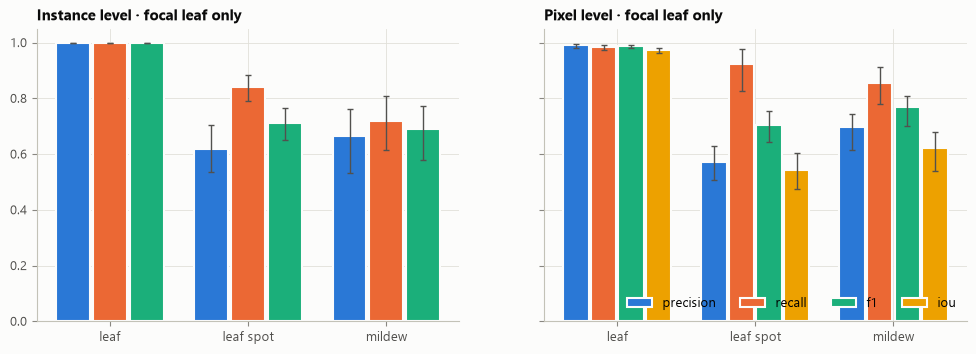

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, level, metrics in ((axes[0], "instance", ("precision", "recall", "f1")), (axes[1], "pixel", ("precision", "recall", "f1", "iou"))):
    x = np.arange(3); wbar = 0.8 / len(metrics)
    for j, m in enumerate(metrics):
        vals = [RESULTS[f"{level}.{c}.{m}"] for c in CLASSES[1:]]
        y = np.array([v["value"] for v in vals])
        err = [y - [v["ci95"][0] for v in vals], [v["ci95"][1] for v in vals] - y]
        ax.bar(x + (j - (len(metrics) - 1) / 2) * wbar, y, wbar * 0.92, yerr=err, color=METRIC_COLOR[m], edgecolor=SURFACE,
               linewidth=1.5, error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 2}, label=m)
    ax.set_xticks(x, ["leaf", "leaf spot", "mildew"]); ax.set_ylim(0, 1.05)
    ax.set_title(f"{level.capitalize()} level · focal leaf only")
axes[1].legend(loc="lower right", ncols=4)
fig.savefig(OUT / "focal_leaf_metrics.png"); plt.show()

## Per photo

In [6]:
print(f"{'photo':<10}{'leaf IoU':>9}{'spots TP/FP/FN':>16}{'mildew TP/FP/FN':>17}{'spot % lab→pred':>18}{'mildew % lab→pred':>20}{'other leaves':>14}")
rows_csv = []
for p in per_image:
    lp = p["pix"]["leaf"]; liou = lp["tp"] / max(lp["tp"] + lp["fp"] + lp["fn"], 1)
    s, m = p["inst"]["leaf_spot"], p["inst"]["powdery_mildew"]
    print(f"{p['file'][9:15]:<10}{liou:>9.2f}{'/'.join(map(str, s)):>16}{'/'.join(map(str, m)):>17}"
          f"{p['cov_gt']['leaf_spot']:>9.2f} → {p['cov_pred']['leaf_spot']:<6.2f}{p['cov_gt']['powdery_mildew']:>10.2f} → {p['cov_pred']['powdery_mildew']:<7.2f}"
          f"{p['other_leaves_ignored']:>12}")
    rows_csv.append({"file": p["file"], "leaf_iou": round(liou, 4), "spot_tp_fp_fn": "/".join(map(str, s)),
                     "mildew_tp_fp_fn": "/".join(map(str, m)), **{f"gt_{d}": round(p["cov_gt"][d], 3) for d in DISEASES},
                     **{f"pred_{d}": round(p["cov_pred"][d], 3) for d in DISEASES}, "other_leaves_ignored": p["other_leaves_ignored"]})

photo      leaf IoU  spots TP/FP/FN  mildew TP/FP/FN   spot % lab→pred   mildew % lab→pred  other leaves
181552         0.96           9/7/3            4/6/5     0.39 → 0.45        1.18 → 0.85             20
183151         0.94           4/4/2           22/6/7     0.24 → 0.50        5.66 → 6.41             12
184402         0.97         15/15/2            6/7/7     0.45 → 0.82        1.18 → 1.39             28
193717         0.98           2/2/0            8/8/1     0.05 → 0.08        0.75 → 1.49              3
194327         0.98          13/8/1           11/7/4     0.49 → 0.89        2.36 → 3.38             20
195635         0.98           4/3/1           12/2/3     0.18 → 0.38        2.72 → 3.38             18
200649         0.98          15/3/3           16/3/2     0.47 → 0.60        3.84 → 4.64             29
201919         0.99          17/7/3            6/4/4     0.51 → 0.75        1.44 → 1.76              4


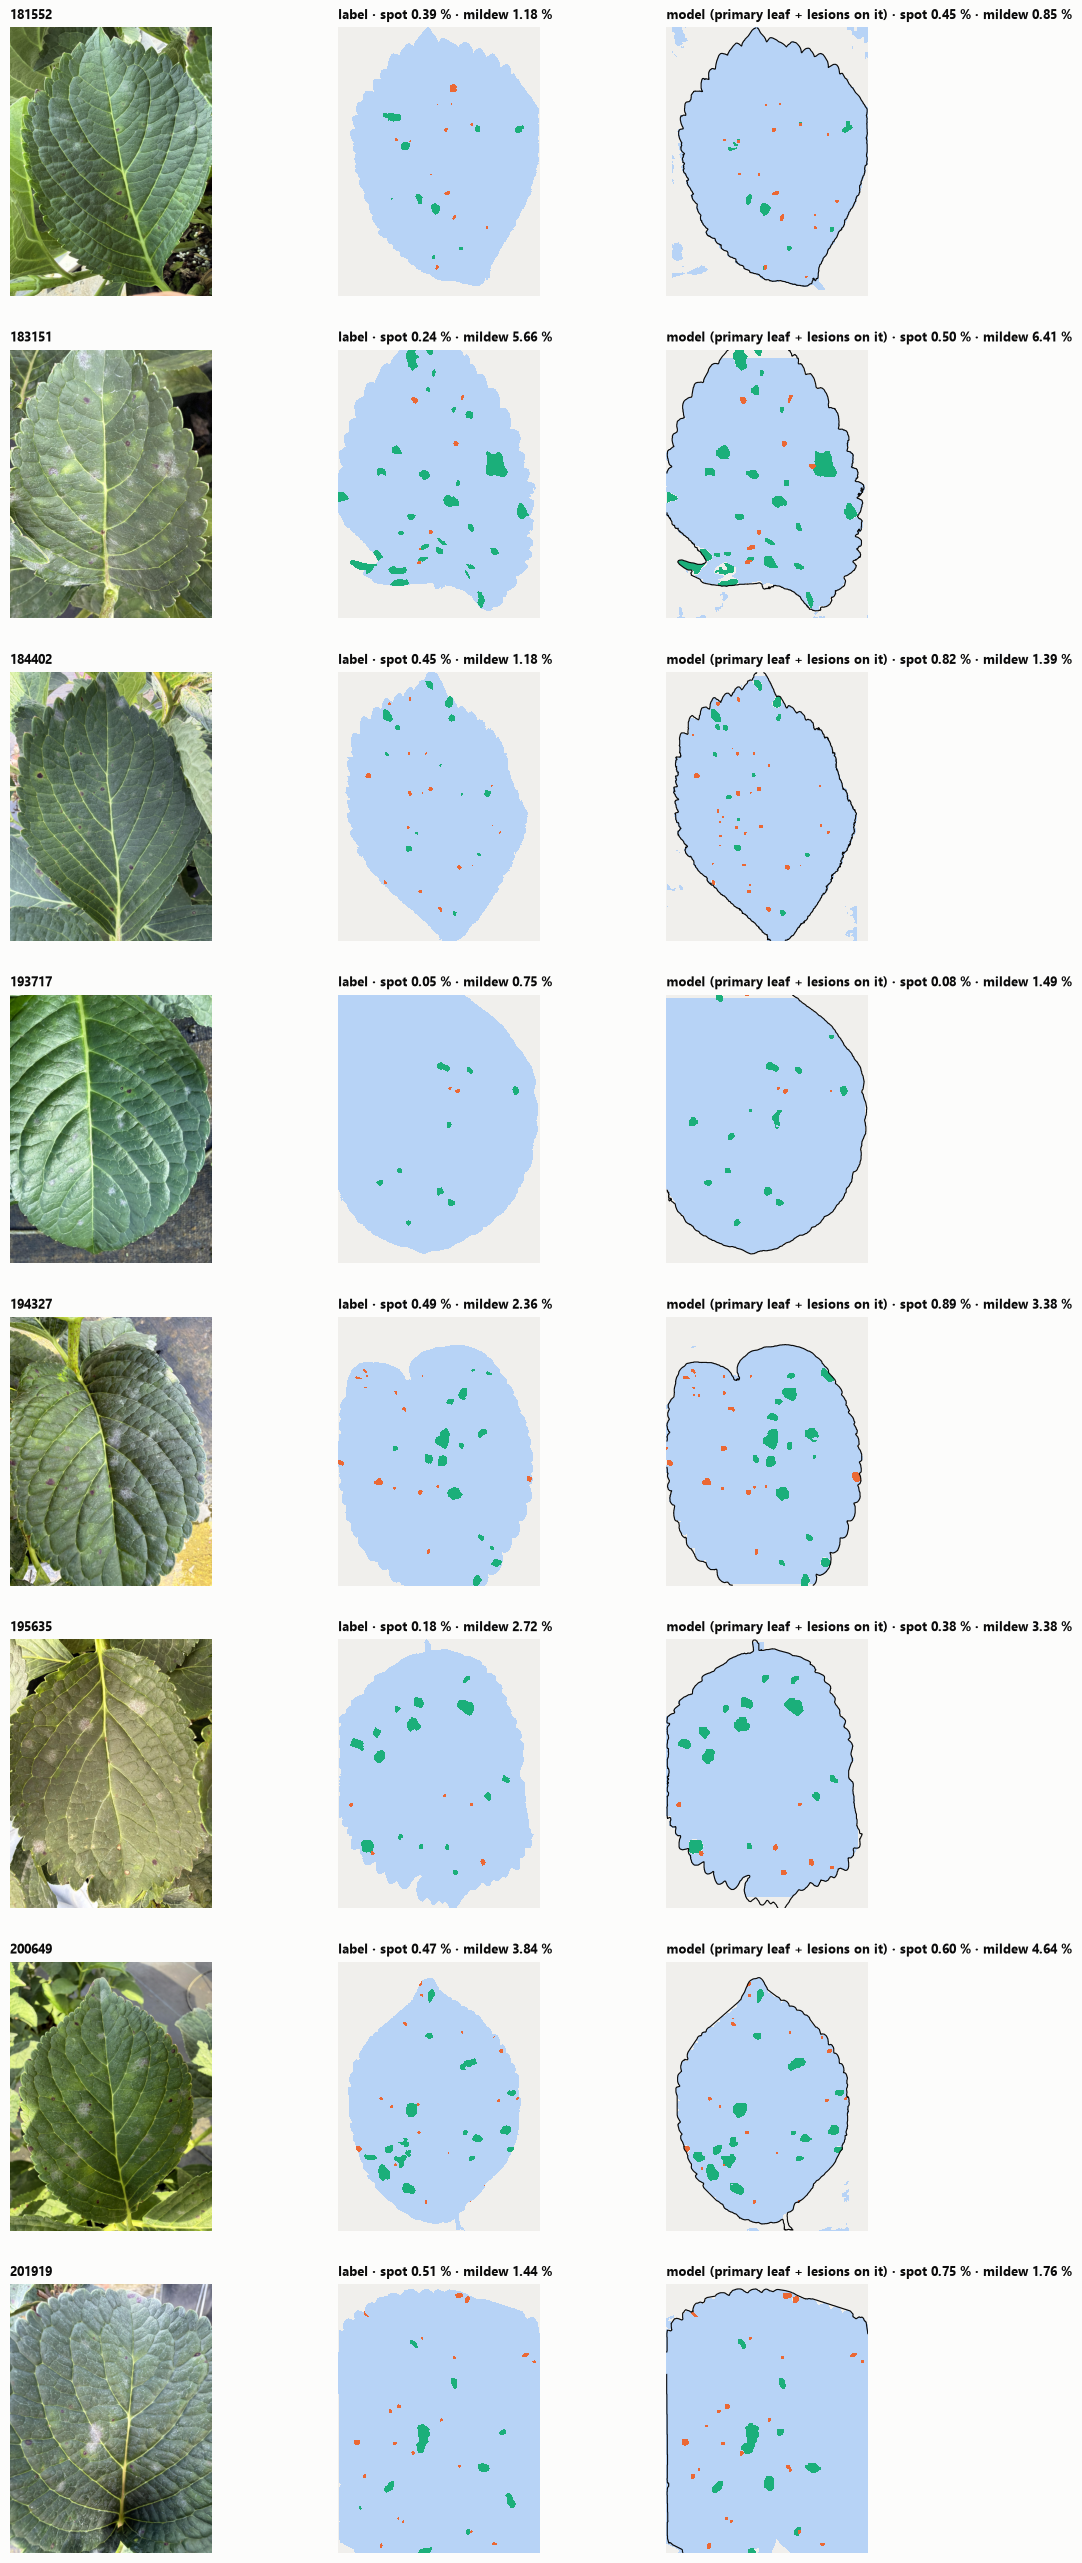

black line = labelled focal leaf


In [7]:
fig, axes = plt.subplots(len(per_image), 3, figsize=(12, 4.1 * len(per_image)))
for axr, p in zip(np.atleast_2d(axes), per_image):
    gt_map, pred_map, leaf_gt = p["maps"]
    axr[0].imshow(p["im"]); axr[0].set_title(p["file"][9:15], fontsize=9)
    axr[1].imshow(np.where(leaf_gt, gt_map, 0), cmap=MAP_COLORS, vmin=0, vmax=3, interpolation="nearest")
    axr[1].set_title(f"label · spot {p['cov_gt']['leaf_spot']:.2f} % · mildew {p['cov_gt']['powdery_mildew']:.2f} %", fontsize=9)
    axr[2].imshow(pred_map, cmap=MAP_COLORS, vmin=0, vmax=3, interpolation="nearest")
    axr[2].contour(leaf_gt, levels=[0.5], colors=[INK], linewidths=0.8)
    axr[2].set_title(f"model (primary leaf + lesions on it) · spot {p['cov_pred']['leaf_spot']:.2f} % · mildew {p['cov_pred']['powdery_mildew']:.2f} %", fontsize=9)
    for ax in axr:
        ax.axis("off")
fig.savefig(OUT / "per_photo.png", dpi=90); plt.show()
print("black line = labelled focal leaf")

## Ultralytics `val` on the focal leaf only

Every photo is greyed out except the labelled focal leaf (2-px edge, no margin), so there are no neighbouring leaves
to produce unlabelled predictions. The labels are unchanged.

In [8]:
src = Path(yolo_yaml).parent / "test"
iso = OUT / "focal_only_yolo"
shutil.rmtree(iso, ignore_errors=True)
(iso / "images").mkdir(parents=True); (iso / "labels").mkdir()
kernel = np.ones((5, 5), np.uint8)
for p in per_image:
    keep = cv2.dilate(p["maps"][2].astype(np.uint8), kernel).astype(bool)
    Image.fromarray(np.where(keep[..., None], np.asarray(p["im"]), np.array(GREY, np.uint8))).save(iso / "images" / p["file"], quality=95)
    shutil.copy(src / "labels" / (Path(p["file"]).stem + ".txt"), iso / "labels")
names = yaml.safe_load(open(yolo_yaml))["names"]
assert list(names) == list(model.names.values()), f"class order differs: {names}"
yaml.safe_dump({"path": str(iso), "train": "images", "val": "images", "names": names}, open(OUT / "focal_only.yaml", "w"))
val = model.val(data=str(OUT / "focal_only.yaml"), imgsz=APP_IMGSZ, batch=4, conf=0.001, iou=0.7, workers=0, plots=True,
                project=str(OUT), name="ultralytics_focal_only", exist_ok=True, verbose=True)
print(f"\nmask mAP50 {val.seg.map50:.3f} · mAP50-95 {val.seg.map:.3f}")

Ultralytics 8.4.184  Python-3.13.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA RTX PRO 5000 Blackwell, 48935MiB)
YOLO26x-seg summary (fused): 204 layers, 62,730,197 parameters, 0 gradients, 313.5 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 747.3±185.5 MB/s, size: 436.3 KB)
val: Scanning C:\Users\bp67339\PCPL\plant disease detection\training\results\focal_leaf_only_powdery-mildew-ds2-scratch-test-v1\focal_only_yolo\labels... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 686.7it/s 0.0s
val: New cache created: C:\Users\bp67339\PCPL\plant disease detection\training\results\focal_leaf_only_powdery-mildew-ds2-scratch-test-v1\focal_only_yolo\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 4.4it/s 0.5s0.7s
                   all          8        220      0.807      0.833      0.861      0.626      0.831      0.769      0.839      0.591
                  leaf 

MaskPR_curve.png


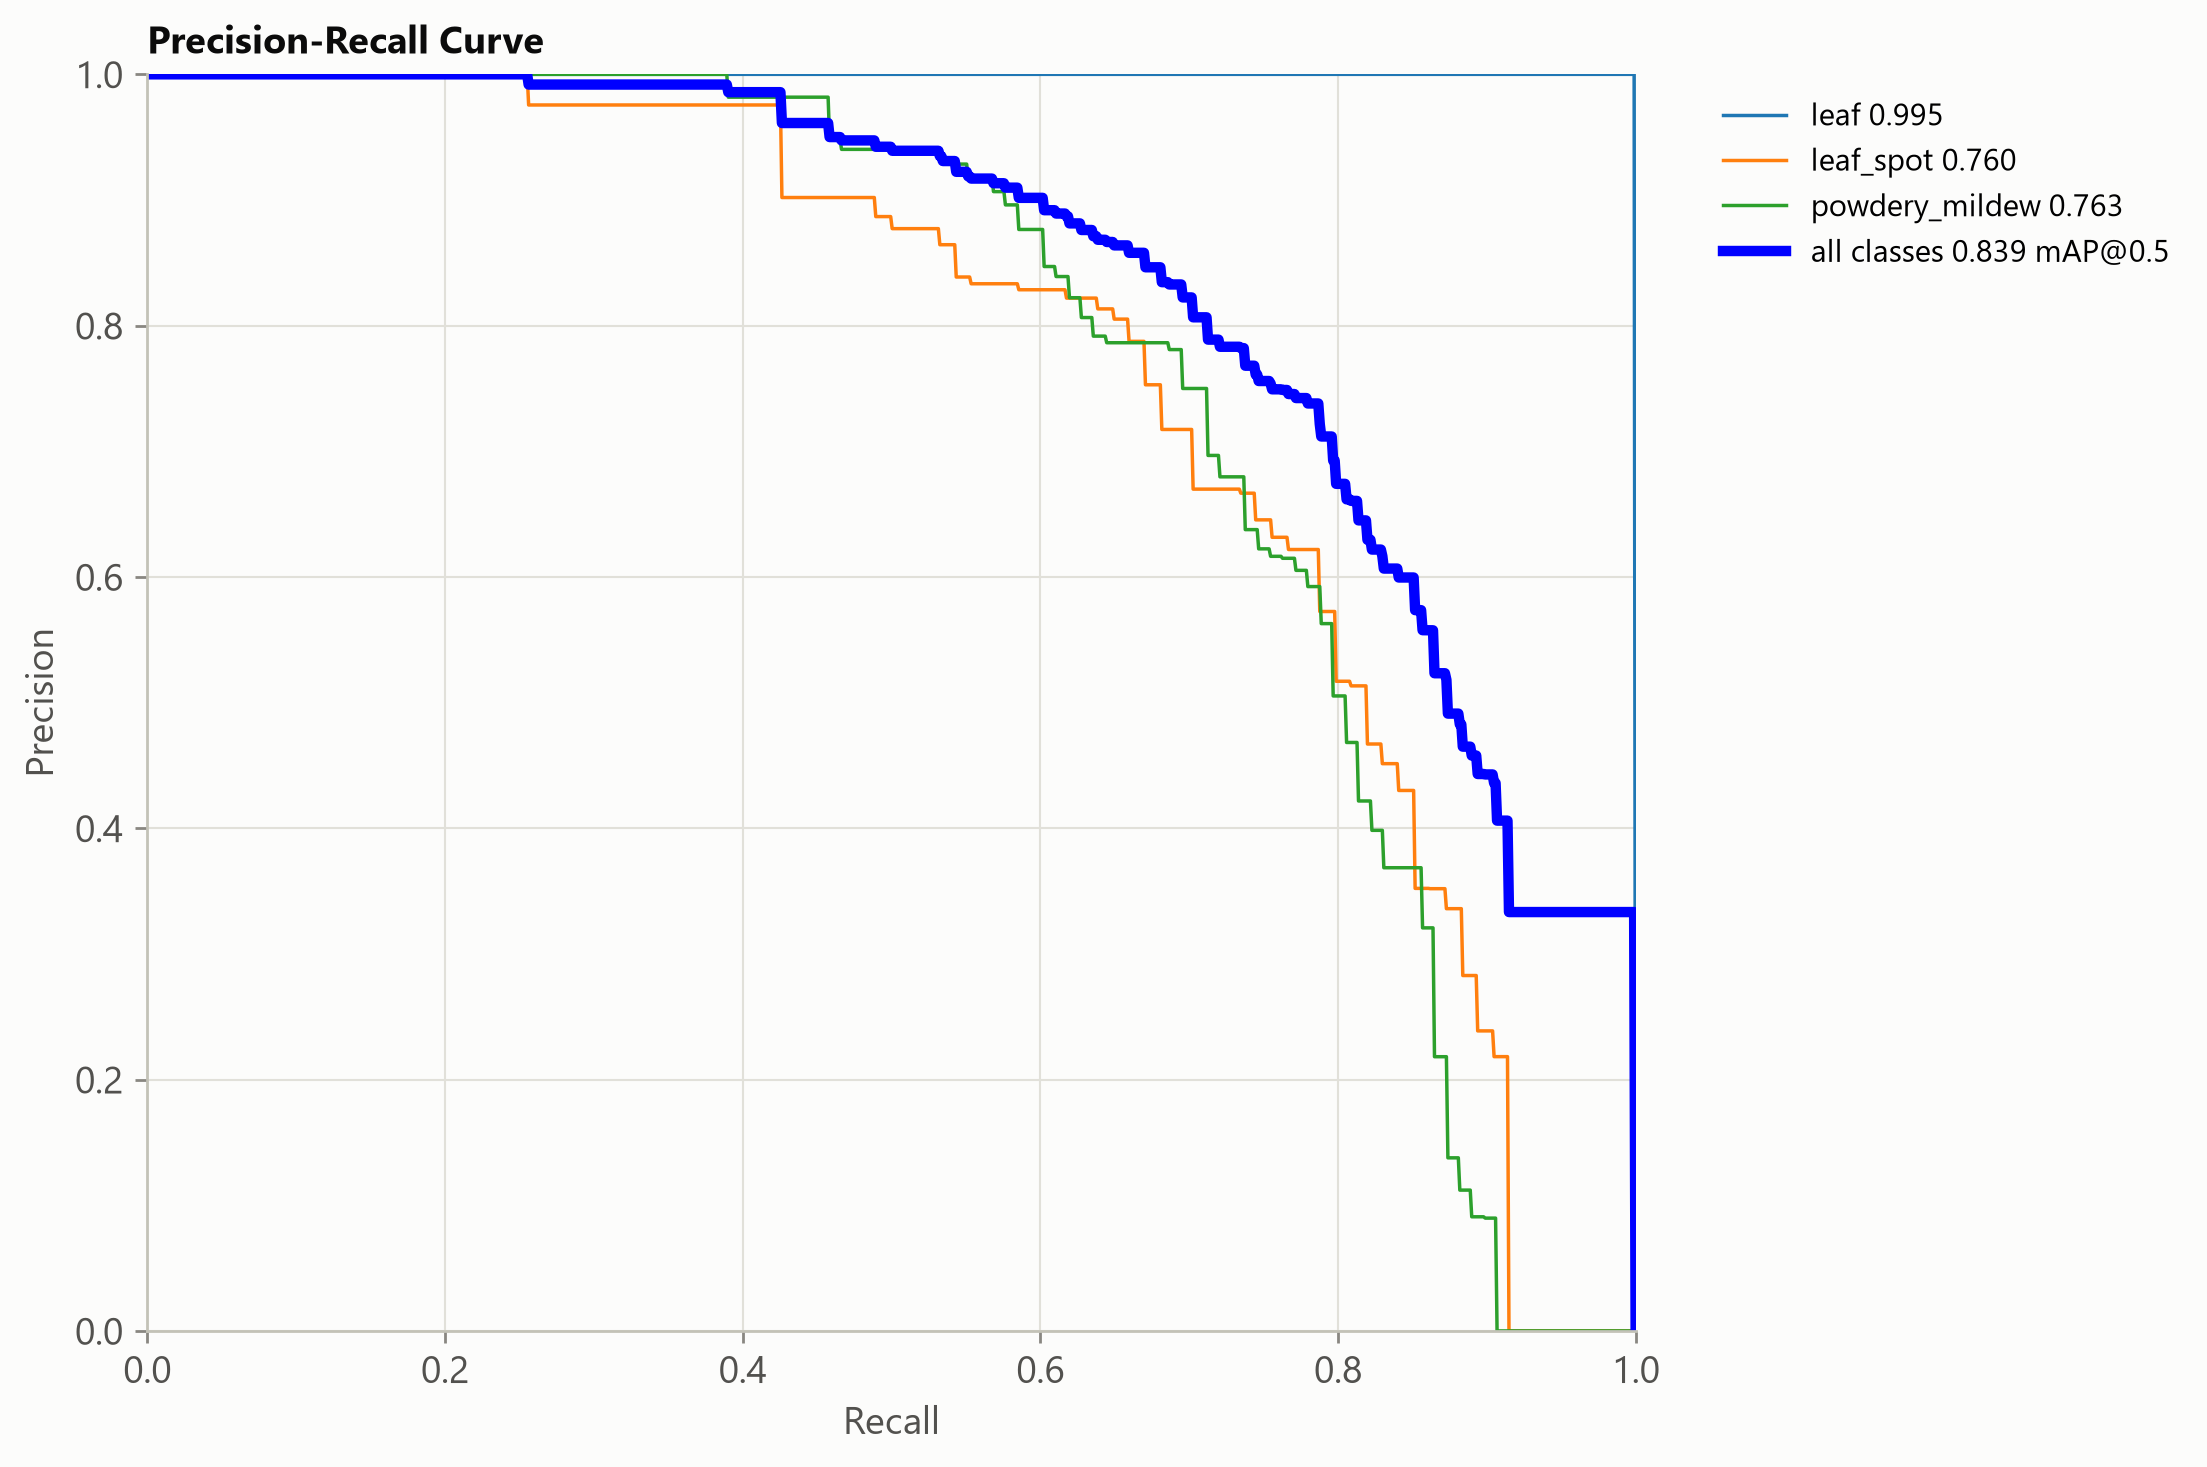

confusion_matrix_normalized.png


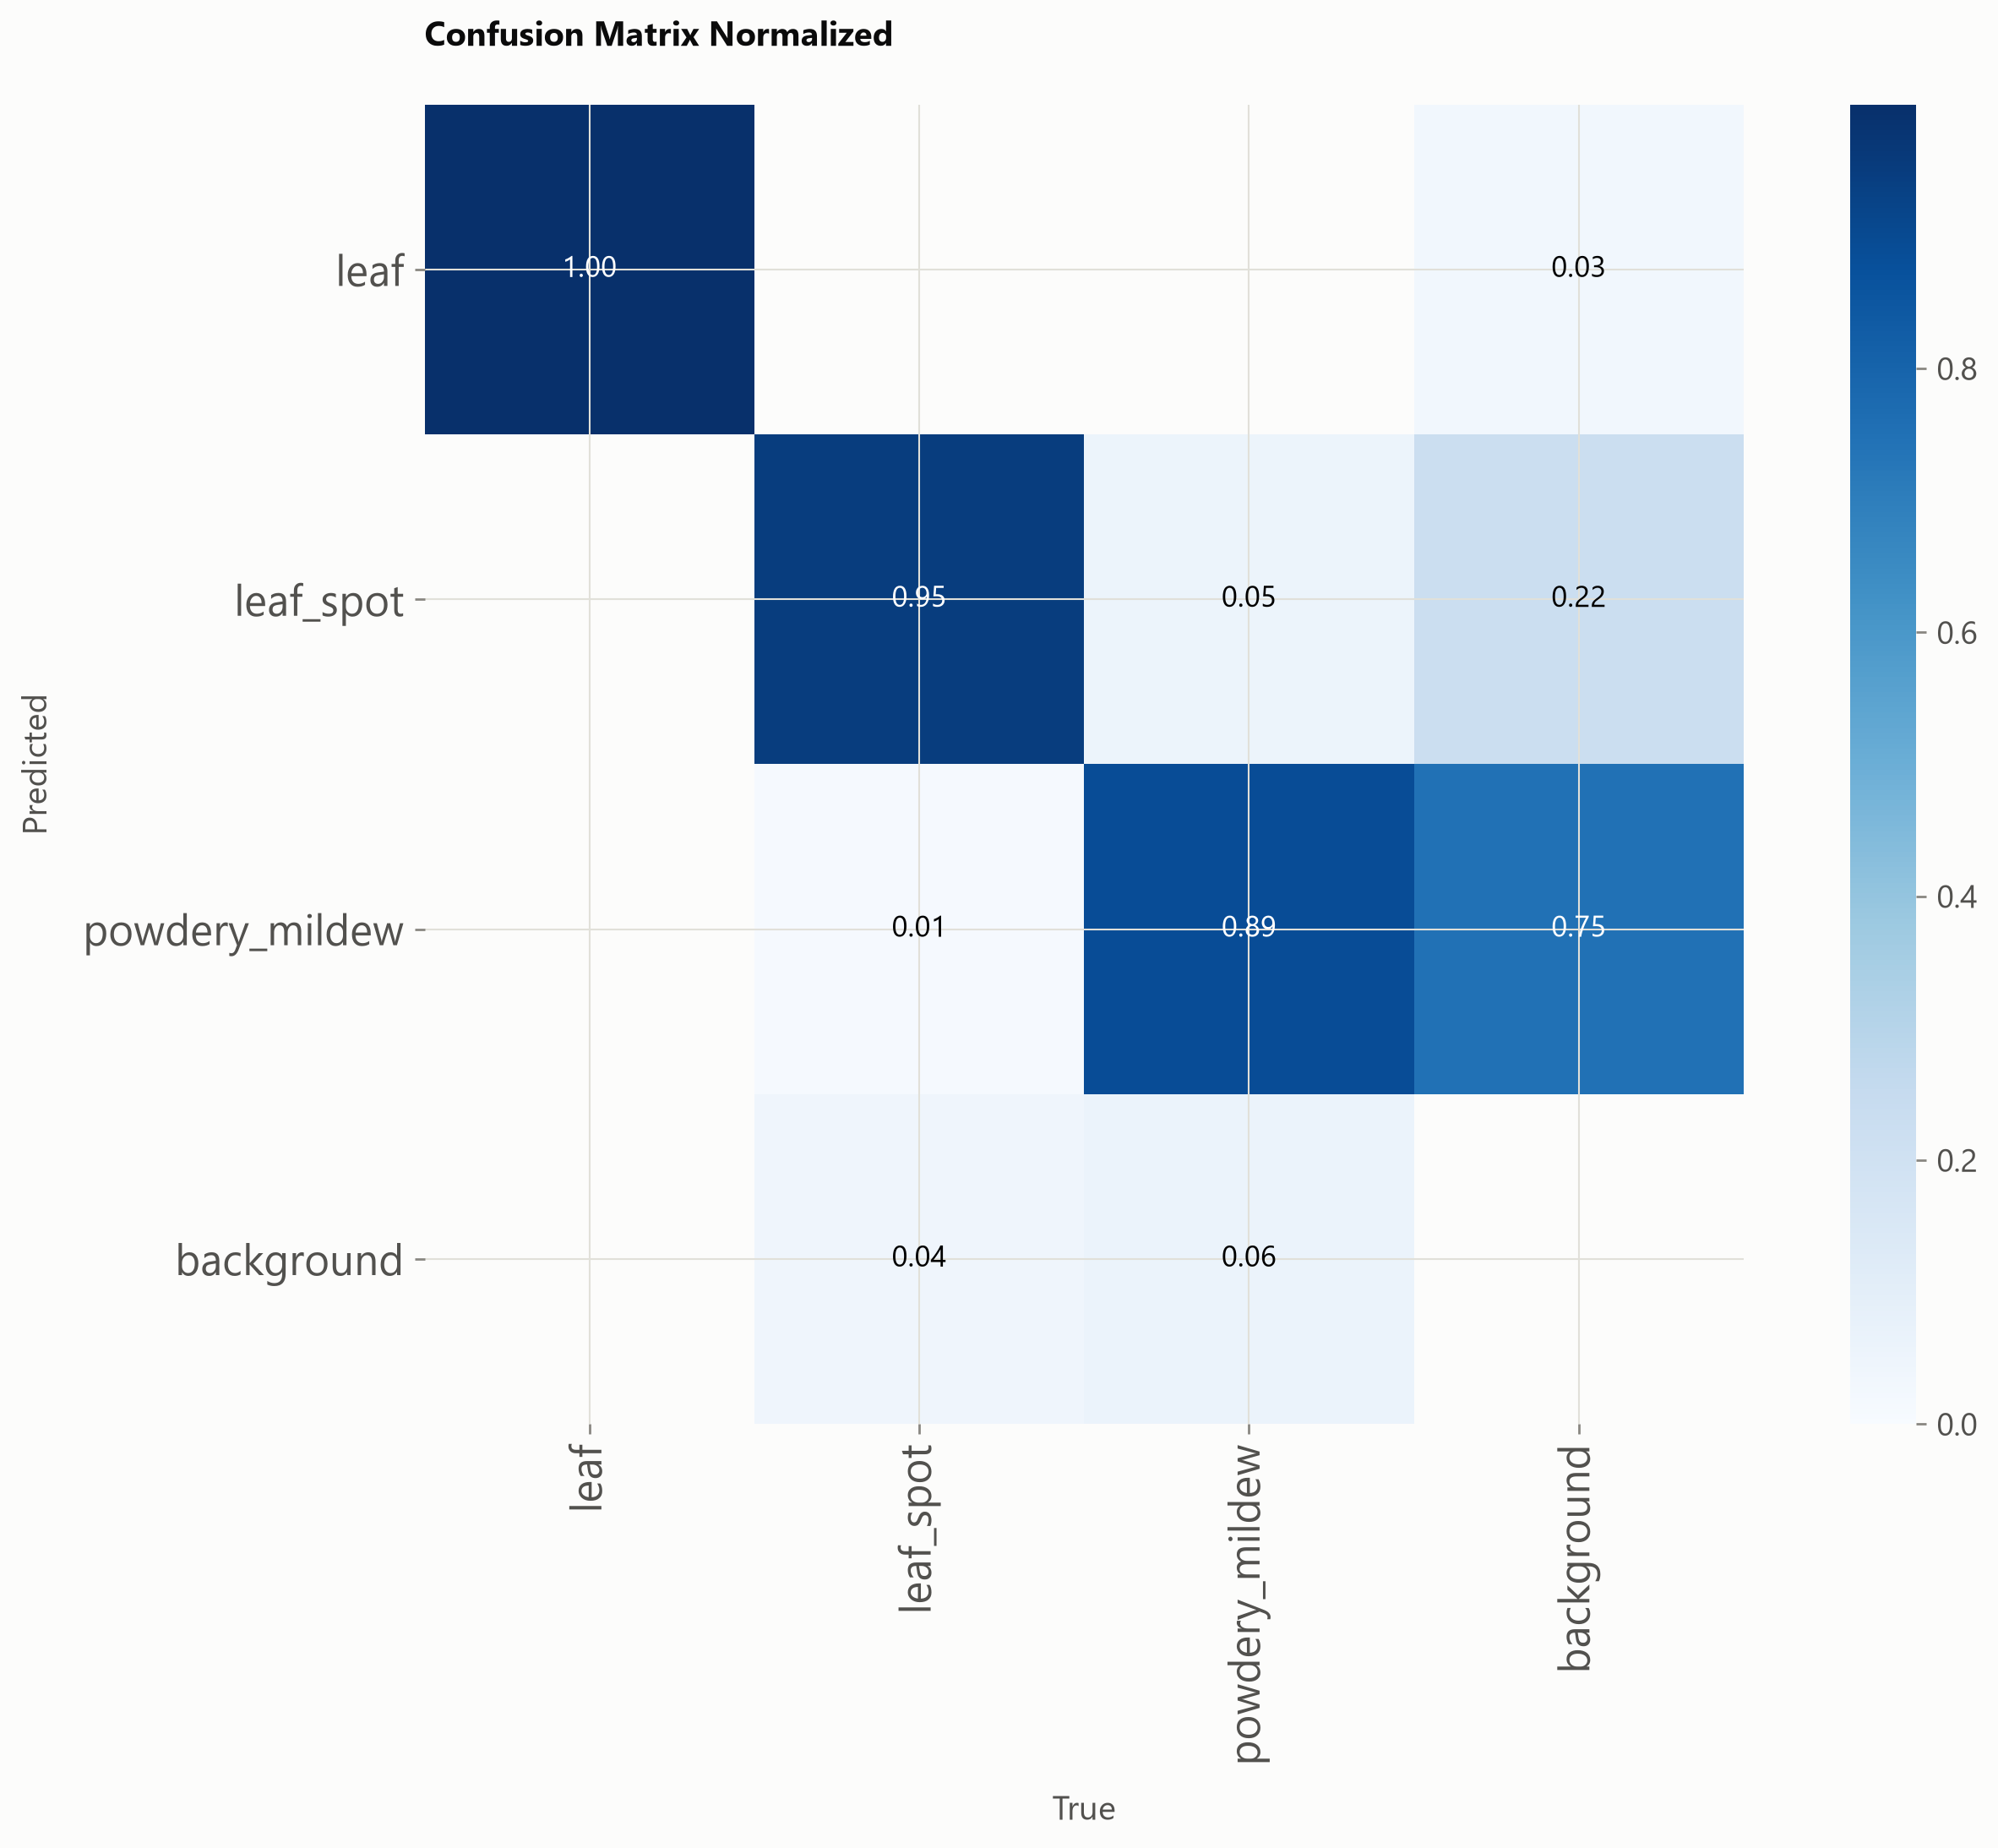

val_batch0_pred.jpg


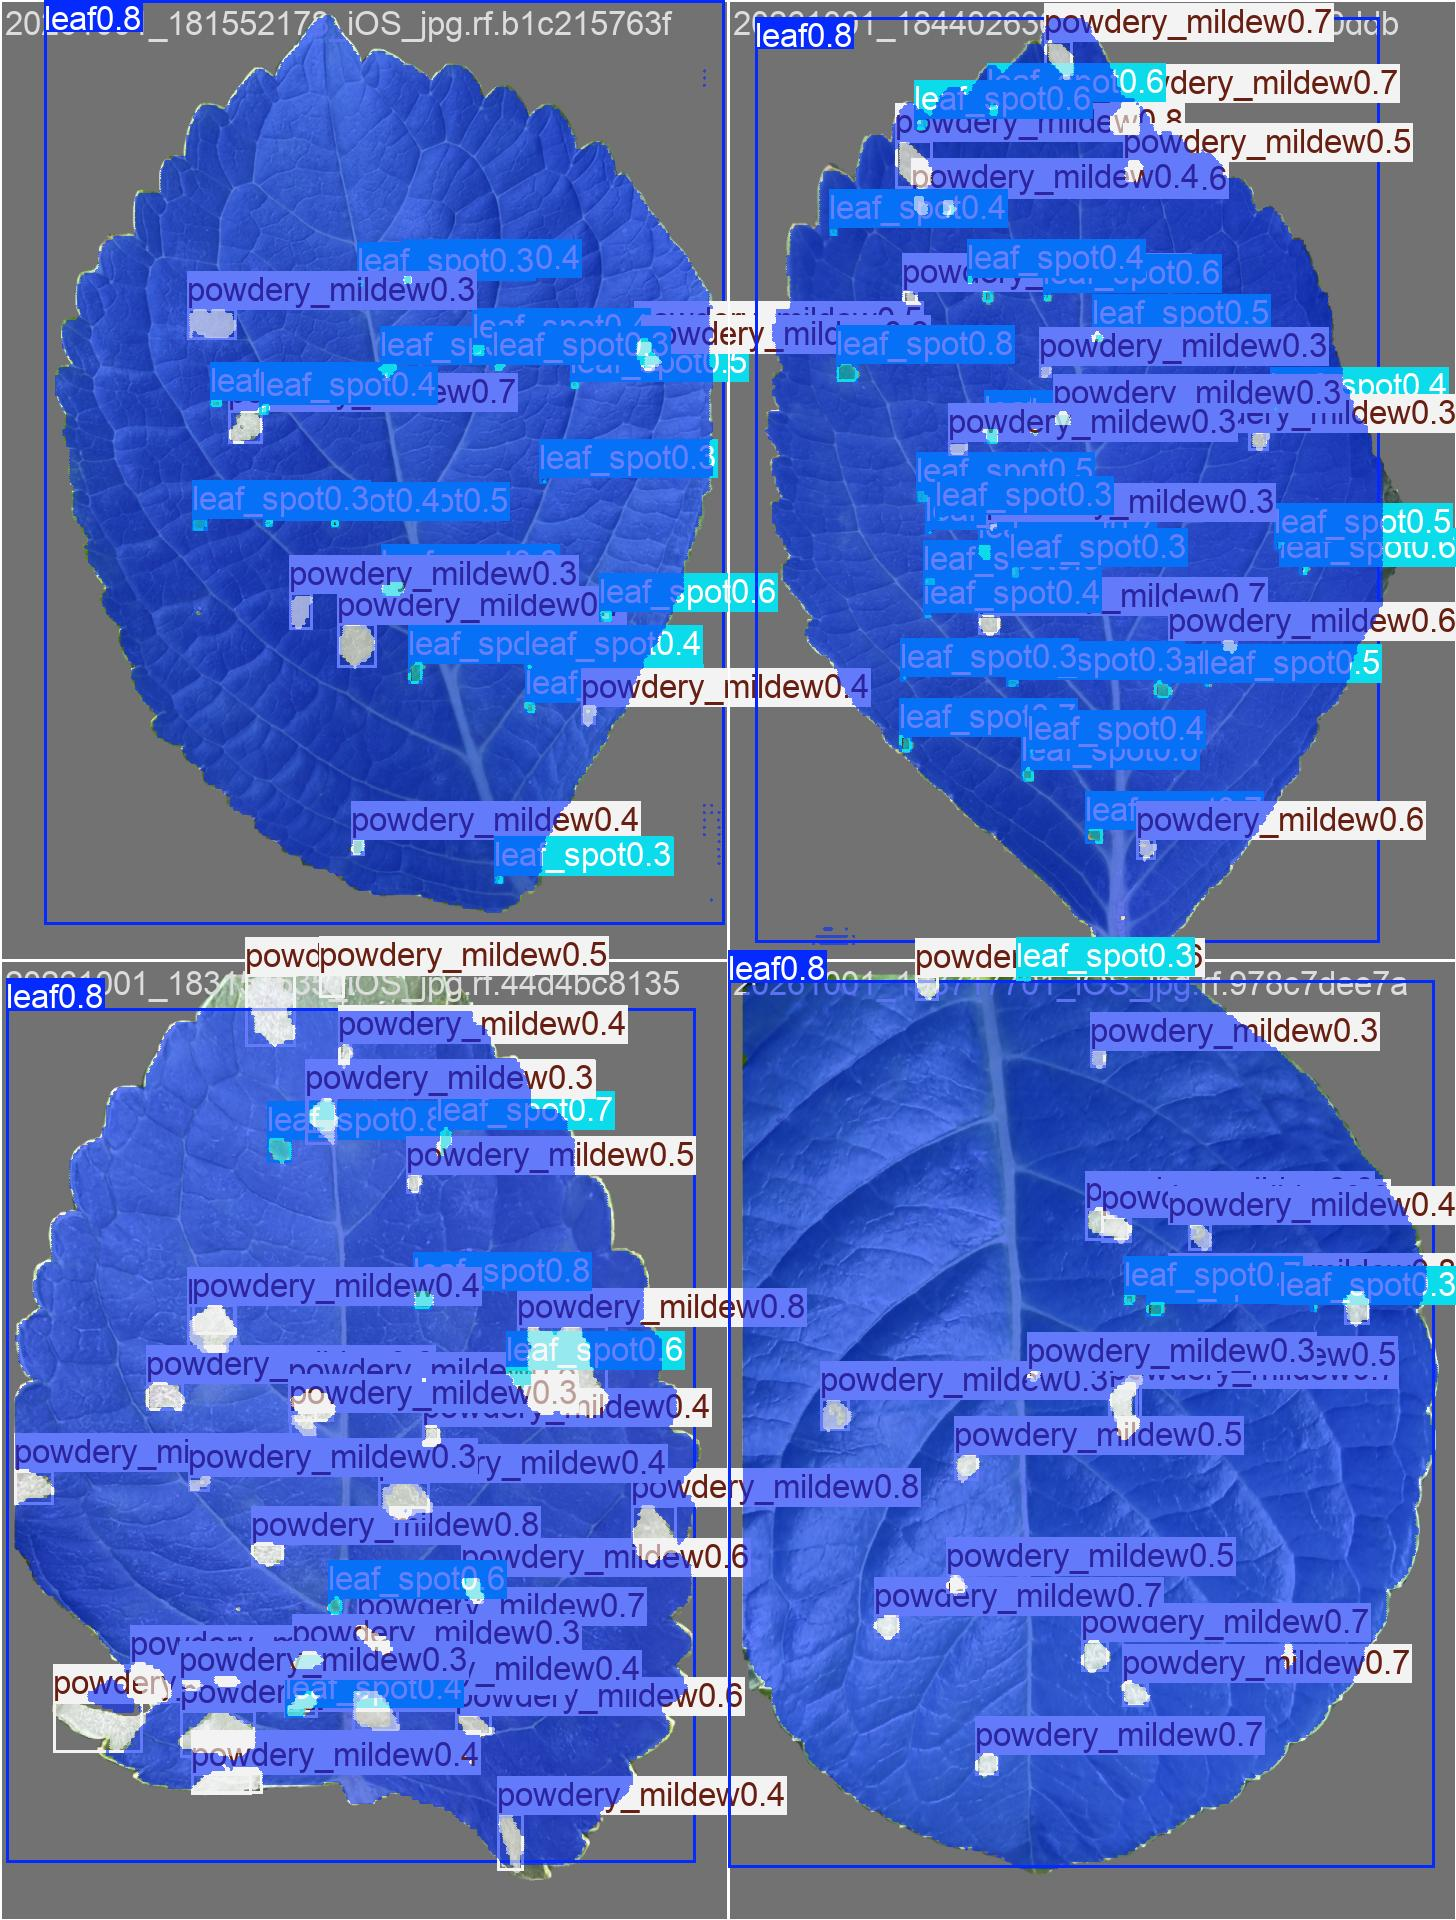

In [9]:
for fname in ("MaskPR_curve.png", "confusion_matrix_normalized.png", "val_batch0_pred.jpg"):
    path = OUT / "ultralytics_focal_only" / fname
    if path.exists():
        print(fname); display(IPImage(filename=str(path), width=760))

## Save

In [10]:
with open(OUT / "per_image.csv", "w", newline="") as fh:
    wr = csv.DictWriter(fh, fieldnames=list(rows_csv[0])); wr.writeheader(); wr.writerows(rows_csv)
json.dump({"project": PROJECT, "version": VERSION, "checkpoint": str(CHECKPOINT.relative_to(ROOT)), "thresholds": THRESH,
           "match_iou": MATCH_IOU, "photos": len(per_image), "metrics": RESULTS, "mask_ap": AP,
           "ultralytics_focal_only": {"map50": float(val.seg.map50), "map50_95": float(val.seg.map)}},
          open(OUT / "metrics.json", "w"), indent=1)
print("saved:", sorted(p.name for p in OUT.iterdir()))

saved: ['focal_leaf_metrics.png', 'focal_only.yaml', 'focal_only_yolo', 'metrics.json', 'per_image.csv', 'per_photo.png', 'ultralytics_focal_only']
